
# Monte Carlo Option Pricing & Risk Analysis

## Project Overview

This project implements Monte Carlo simulation to price a European call option and evaluates the results against the Black-Scholes analytical model.

It also explores how option prices respond to changes in market parameters and measures the risk of a long call position.

### Key Features
- Geometric Brownian Motion (GBM) stock price simulation
- European call option pricing using Monte Carlo
- Convergence analysis and Black-Scholes comparison
- Sensitivity analysis for volatility, strike price, and stock price
- Option Greeks: Delta, Gamma, Vega, Theta, and Rho
- Value at Risk (VaR) and Conditional Value at Risk (CVaR)
- Profit/loss distribution visualization

### Model Assumptions
- Initial stock price: €100
- Strike price: €110
- Time to maturity: 1 year
- Volatility: 20%
- Risk-free interest rate: 3%
- Assumed real-world expected return: 8%

Risk-neutral simulations are used for option pricing, while simulations under the assumed real-world drift are used for the risk analysis. The results are model-based and do not represent actual market forecasts.



## 1. Stock Price Simulation

We simulate possible future stock prices using Geometric Brownian Motion (GBM).


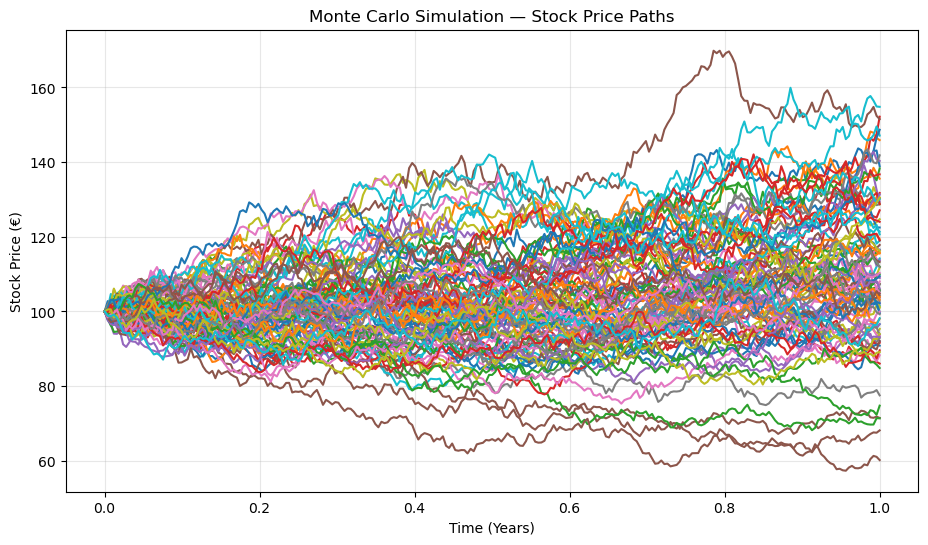

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Initial parameters
S0 = 100          # Initial stock price (€)
mu = 0.08         # Expected annual return (8%)
sigma = 0.20      # Annual volatility (20%)
T = 1             # Time horizon: 1 year
steps = 252       # Trading days in one year
simulations = 100 # Number of simulated price paths

dt = T / steps
rng = np.random.default_rng(42)

# Generate random daily shocks
Z = rng.standard_normal((steps, simulations))

# Simulate stock prices using Geometric Brownian Motion
daily_returns = np.exp(
    (mu - 0.5 * sigma**2) * dt
    + sigma * np.sqrt(dt) * Z
)

prices = np.vstack([
    np.full(simulations, S0),
    S0 * np.cumprod(daily_returns, axis=0)
])

# Plot simulated stock price paths
plt.figure(figsize=(11, 6))
plt.plot(np.linspace(0, T, steps + 1), prices)
plt.title("Monte Carlo Simulation — Stock Price Paths")
plt.xlabel("Time (Years)")
plt.ylabel("Stock Price (€)")
plt.grid(alpha=0.3)
plt.show()


## 2. European Call Option Payoff

We calculate the payoff of a European call option at maturity.

The option gives its holder the right, but not the obligation, to buy the underlying stock at the strike price.

The payoff is calculated as:

**Payoff = max(Stock Price at Maturity - Strike Price, 0)**

The payoff does not include the premium paid to purchase the option.


In [2]:
K = 110

final_prices = prices[-1, :]

payoffs = np.maximum(final_prices - K, 0)

print("First 5 final prices:", final_prices[:5])
print("First 5 option payoffs:", payoffs[:5])

First 5 final prices: [138.89589562 145.90268905 105.74740546 127.08274172  91.98190904]
First 5 option payoffs: [28.89589562 35.90268905  0.         17.08274172  0.        ]



## 3. Risk-Neutral Monte Carlo Pricing

To estimate the theoretical price of a European call option, we simulate stock prices under the risk-neutral measure.

Under risk-neutral pricing, the expected stock return is replaced by the risk-free interest rate (r), rather than the assumed real-world return (mu).

For each simulated stock price at maturity, we calculate the call option payoff:

**Payoff = max(S_T - K, 0)**

The theoretical option price is obtained by averaging the simulated payoffs and discounting the result to its present value:

**Option Price = exp(-rT) × Average Payoff**

This approach allows us to estimate the option's theoretical value today using Monte Carlo simulation.


In [3]:
r = 0.03

risk_neutral_returns = np.exp(
    (r - 0.5 * sigma**2) * dt
    + sigma * np.sqrt(dt) * Z
)

risk_neutral_prices = np.vstack([
    np.full(simulations, S0),
    S0 * np.cumprod(risk_neutral_returns, axis=0)
])

print(risk_neutral_prices[-1, :5])

[132.12186285 138.78693094 100.59004364 120.88484327  87.4958984 ]


In [4]:
rn_final_prices = risk_neutral_prices[-1, :]

rn_payoffs = np.maximum(rn_final_prices - K, 0)

average_payoff = np.mean(rn_payoffs)

print("Average payoff:", average_payoff)

Average payoff: 5.229082553414537


In [5]:
option_price = np.exp(-r * T) * average_payoff

print("European Call Option Price:", round(option_price, 2))

European Call Option Price: 5.07



## 4. Monte Carlo Convergence Analysis

Monte Carlo pricing uses random simulations, so the estimated option price can vary depending on the number of simulated scenarios.

In this section, we compare option prices calculated using different simulation counts, ranging from 100 to 50,000.

As the number of simulations increases, the estimate generally becomes more stable and tends to approach the theoretical option value.

This analysis helps us evaluate the numerical accuracy and convergence behavior of our Monte Carlo pricing method.


In [6]:
def calculate_option_price(n_simulations):
    rng = np.random.default_rng(42)

    Z = rng.standard_normal((steps, n_simulations))

    daily_returns = np.exp(
        (r - 0.5 * sigma**2) * dt
        + sigma * np.sqrt(dt) * Z
    )

    final_prices = S0 * np.prod(daily_returns, axis=0)

    payoffs = np.maximum(final_prices - K, 0)

    option_price = np.exp(-r * T) * np.mean(payoffs)

    return option_price


print("100 simulations:", calculate_option_price(100))
print("1,000 simulations:", calculate_option_price(1000))
print("10,000 simulations:", calculate_option_price(10000))

100 simulations: 5.074539808517566
1,000 simulations: 5.585647246128046
10,000 simulations: 5.408374969807695


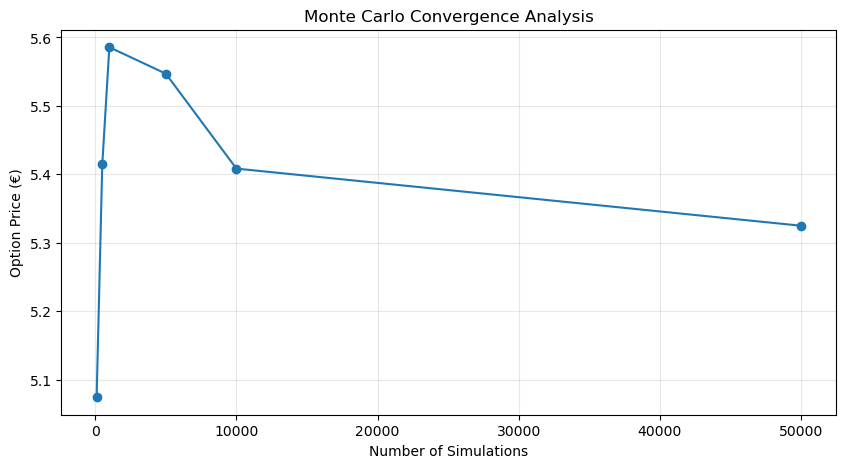

In [7]:
simulation_counts = [100, 500, 1000, 5000, 10000, 50000]

option_prices = []

for n in simulation_counts:
    price = calculate_option_price(n)
    option_prices.append(price)

plt.figure(figsize=(10, 5))
plt.plot(simulation_counts, option_prices, marker="o")

plt.xlabel("Number of Simulations")
plt.ylabel("Option Price (€)")
plt.title("Monte Carlo Convergence Analysis")
plt.grid(alpha=0.3)
plt.show()


## 5. Black-Scholes Model Validation

The Black-Scholes model provides an analytical formula for pricing European call options under specific assumptions.

We use Black-Scholes as a benchmark to evaluate the accuracy of our Monte Carlo pricing implementation.

Both approaches use the same stock price, strike price, volatility, risk-free interest rate, and time to maturity.

The Black-Scholes call price is:

**C = S0 × N(d1) − K × exp(−rT) × N(d2)**

Where:
- S0: Initial stock price
- K: Strike price
- r: Risk-free interest rate
- T: Time to maturity
- N(x): Standard normal cumulative distribution function

A small difference between Monte Carlo and Black-Scholes prices provides evidence that our simulation is consistent with the analytical model.


In [8]:
from scipy.stats import norm

d1 = (
    np.log(S0 / K)
    + (r + 0.5 * sigma**2) * T
) / (sigma * np.sqrt(T))

d2 = d1 - sigma * np.sqrt(T)

bs_price = (
    S0 * norm.cdf(d1)
    - K * np.exp(-r * T) * norm.cdf(d2)
)

print("Black-Scholes Price:", round(bs_price, 2))

Black-Scholes Price: 5.29



## 6. Option Price Sensitivity Analysis

Sensitivity analysis examines how the theoretical price of a European call option changes when individual model parameters are varied while other parameters remain constant.

We investigate three key factors:

### 6.1 Volatility

Volatility measures the magnitude of stock price fluctuations.

Higher volatility generally increases the value of a European call option because it creates greater upside potential while the option buyer's downside remains limited to the premium paid.

### 6.2 Strike Price

The strike price is the predetermined price at which the option holder has the right to purchase the underlying stock.

A higher strike price generally reduces the value of a call option, holding other factors constant.

### 6.3 Initial Stock Price

The initial stock price is the current market price of the underlying asset.

A higher stock price generally increases the value of a call option, holding other factors constant.

These relationships are illustrated using the Black-Scholes pricing model.


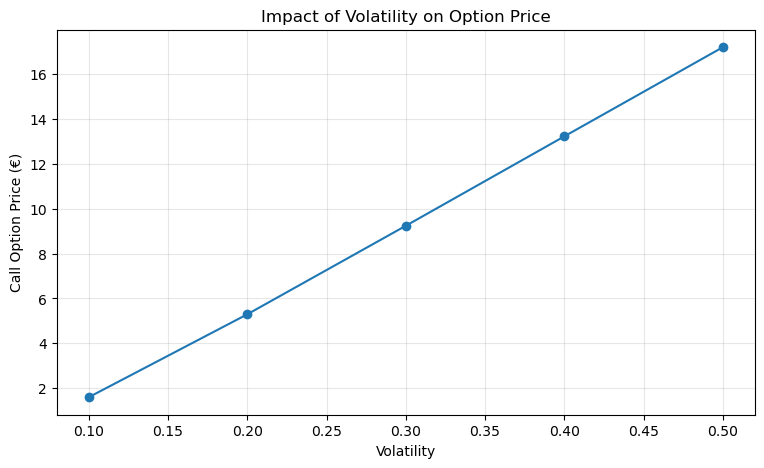

In [9]:
volatilities = [0.10, 0.20, 0.30, 0.40, 0.50]

option_values = []

for vol in volatilities:
    d1 = (
        np.log(S0 / K)
        + (r + 0.5 * vol**2) * T
    ) / (vol * np.sqrt(T))

    d2 = d1 - vol * np.sqrt(T)

    price = (
        S0 * norm.cdf(d1)
        - K * np.exp(-r * T) * norm.cdf(d2)
    )

    option_values.append(price)

plt.figure(figsize=(9, 5))
plt.plot(volatilities, option_values, marker="o")

plt.xlabel("Volatility")
plt.ylabel("Call Option Price (€)")
plt.title("Impact of Volatility on Option Price")
plt.grid(alpha=0.3)
plt.show()

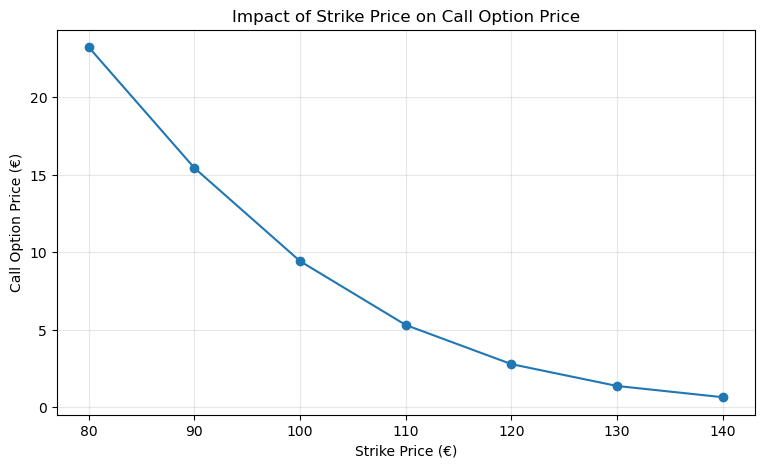

In [10]:
strike_prices = [80, 90, 100, 110, 120, 130, 140]

strike_option_values = []

for strike in strike_prices:
    d1 = (
        np.log(S0 / strike)
        + (r + 0.5 * sigma**2) * T
    ) / (sigma * np.sqrt(T))

    d2 = d1 - sigma * np.sqrt(T)

    price = (
        S0 * norm.cdf(d1)
        - strike * np.exp(-r * T) * norm.cdf(d2)
    )

    strike_option_values.append(price)

plt.figure(figsize=(9, 5))
plt.plot(strike_prices, strike_option_values, marker="o")

plt.xlabel("Strike Price (€)")
plt.ylabel("Call Option Price (€)")
plt.title("Impact of Strike Price on Call Option Price")
plt.grid(alpha=0.3)
plt.show()

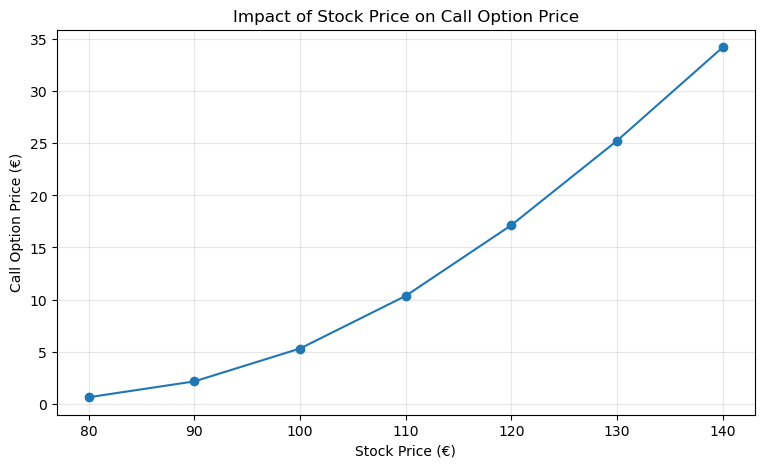

In [11]:
stock_prices = [80, 90, 100, 110, 120, 130, 140]

stock_option_values = []

for stock in stock_prices:
    d1 = (
        np.log(stock / K)
        + (r + 0.5 * sigma**2) * T
    ) / (sigma * np.sqrt(T))

    d2 = d1 - sigma * np.sqrt(T)

    price = (
        stock * norm.cdf(d1)
        - K * np.exp(-r * T) * norm.cdf(d2)
    )

    stock_option_values.append(price)

plt.figure(figsize=(9, 5))
plt.plot(stock_prices, stock_option_values, marker="o")

plt.xlabel("Stock Price (€)")
plt.ylabel("Call Option Price (€)")
plt.title("Impact of Stock Price on Call Option Price")
plt.grid(alpha=0.3)
plt.show()


## 7. Option Greeks Analysis

Option Greeks measure how an option's theoretical value responds to changes in market conditions and time.

We calculate five Greeks using the Black-Scholes model:

### Delta
Measures the approximate change in option price for a €1 change in the underlying stock price.

### Gamma
Measures how much Delta changes for a €1 change in the underlying stock price.

### Vega
Measures the sensitivity of the option price to changes in volatility. We report Vega for a 1 percentage point increase in volatility.

### Theta
Measures the sensitivity of the option price to the passage of time. We report the approximate daily time decay of the option.

### Rho
Measures the sensitivity of the option price to changes in the risk-free interest rate. We report Rho for a 1 percentage point increase in the interest rate.

These measures help assess the different sources of risk affecting the option's value.


In [12]:
d1 = (
    np.log(S0 / K)
    + (r + 0.5 * sigma**2) * T
) / (sigma * np.sqrt(T))

delta = norm.cdf(d1)

print("Call Option Delta:", round(delta, 4))

Call Option Delta: 0.4104


In [13]:
gamma = norm.pdf(d1) / (S0 * sigma * np.sqrt(T))

vega = S0 * norm.pdf(d1) * np.sqrt(T)

print("Gamma:", round(gamma, 4))
print("Vega:", round(vega, 4))
print("Vega for 1% volatility change:", round(vega * 0.01, 4))

Gamma: 0.0194
Vega: 38.8835
Vega for 1% volatility change: 0.3888


In [14]:
d1 = (
    np.log(S0 / K)
    + (r + 0.5 * sigma**2) * T
) / (sigma * np.sqrt(T))

d2 = d1 - sigma * np.sqrt(T)

theta_annual = (
    -(S0 * norm.pdf(d1) * sigma) / (2 * np.sqrt(T))
    - r * K * np.exp(-r * T) * norm.cdf(d2)
)

theta_daily = theta_annual / 365

rho = K * T * np.exp(-r * T) * norm.cdf(d2)

print("Annual Theta:", round(theta_annual, 4))
print("Daily Theta:", round(theta_daily, 4))
print("Rho:", round(rho, 4))
print("Rho for 1 percentage point:", round(rho * 0.01, 4))

Annual Theta: -4.9607
Daily Theta: -0.0136
Rho: 35.7453
Rho for 1 percentage point: 0.3575


In [15]:
import pandas as pd

results = pd.DataFrame({
    "Metric": [
        "Monte Carlo Price (50,000)",
        "Black-Scholes Price",
        "Delta",
        "Gamma",
        "Vega (1 percentage point)",
        "Theta (daily)",
        "Rho (1 percentage point)"
    ],
    "Value": [
        calculate_option_price(50000),
        bs_price,
        delta,
        gamma,
        vega * 0.01,
        theta_daily,
        rho * 0.01
    ]
})

results["Value"] = results["Value"].round(4)

display(results)

,Metric,Value
0,"Monte Carlo Price (50,000)",5.3250
1,Black-Scholes Price,5.2934
2,Delta,0.4104
3,Gamma,0.0194
4,Vega (1 percentage point),0.3888
5,Theta (daily),-0.0136
6,Rho (1 percentage point),0.3575


In [16]:
premium = bs_price

rn_final_prices = risk_neutral_prices[-1, :]

rn_payoffs = np.maximum(rn_final_prices - K, 0)

net_profits = rn_payoffs - premium

print("First 5 net profits:", np.round(net_profits[:5], 2))
print("Worst possible loss:", round(-premium, 2))

First 5 net profits: [16.83 23.49 -5.29  5.59 -5.29]
Worst possible loss: -5.29



## 8. Risk Analysis: Value at Risk (VaR) and Conditional Value at Risk (CVaR)

This section evaluates the one-year profit and loss distribution of a long European call option.

We use simulated stock prices under the assumed real-world expected return (mu = 8%) rather than the risk-neutral drift used for option pricing.

### 8.1 Profit and Loss

For each scenario, we calculate the payoff at maturity and subtract the initial option premium.

**Net Profit = max(S_T - K, 0) - Premium**

For a purchased call option, the maximum possible loss is limited to the premium paid, excluding transaction costs and financing expenses.

### 8.2 Value at Risk (VaR)

Value at Risk measures a loss threshold at a specified confidence level and time horizon.

We calculate the 95% VaR using the 95th percentile of simulated losses.

### 8.3 Conditional Value at Risk (CVaR)

Conditional Value at Risk, also known as Expected Shortfall, measures the average loss in the worst tail of the loss distribution.

In this project, VaR and CVaR are equal to the option premium because the worst simulated scenarios result in the complete loss of the premium.

### 8.4 Risk Simulation and Visualization

We increase the number of simulated scenarios to 10,000 to examine the profit/loss distribution.

A histogram illustrates the asymmetric payoff structure of a long call option, with limited downside and potentially substantial upside.

### Limitations

The risk analysis assumes constant volatility, a fixed expected return, and a one-year holding period. It does not incorporate transaction costs, changing market conditions, or early liquidation of the option.


In [17]:
premium = bs_price

real_world_final_prices = prices[-1, :]

real_world_payoffs = np.maximum(
    real_world_final_prices - K, 0
)

net_profits = real_world_payoffs - premium

losses = -net_profits

print("First 5 net profits:", np.round(net_profits[:5], 2))
print("First 5 losses:", np.round(losses[:5], 2))

First 5 net profits: [23.6  30.61 -5.29 11.79 -5.29]
First 5 losses: [-23.6  -30.61   5.29 -11.79   5.29]


In [18]:
confidence_level = 0.95

var_95 = np.percentile(losses, 95)

print("95% Value at Risk:", round(var_95, 4))

95% Value at Risk: 5.2934


In [19]:
worst_losses = losses[losses >= var_95]

cvar_95 = np.mean(worst_losses)

print("95% VaR:", round(var_95, 4))
print("95% CVaR:", round(cvar_95, 4))

95% VaR: 5.2934
95% CVaR: 5.2934


In [20]:
risk_simulations = 10000

rng_risk = np.random.default_rng(123)

Z_risk = rng_risk.standard_normal(
    (steps, risk_simulations)
)

risk_daily_returns = np.exp(
    (mu - 0.5 * sigma**2) * dt
    + sigma * np.sqrt(dt) * Z_risk
)

risk_final_prices = S0 * np.prod(
    risk_daily_returns, axis=0
)

risk_payoffs = np.maximum(
    risk_final_prices - K, 0
)

risk_net_profits = risk_payoffs - premium

risk_losses = -risk_net_profits

risk_var_95 = np.percentile(risk_losses, 95)

risk_cvar_95 = np.mean(
    risk_losses[risk_losses >= risk_var_95]
)

print("Number of scenarios:", risk_simulations)
print("95% VaR:", round(risk_var_95, 4))
print("95% CVaR:", round(risk_cvar_95, 4))

Number of scenarios: 10000
95% VaR: 5.2934
95% CVaR: 5.2934


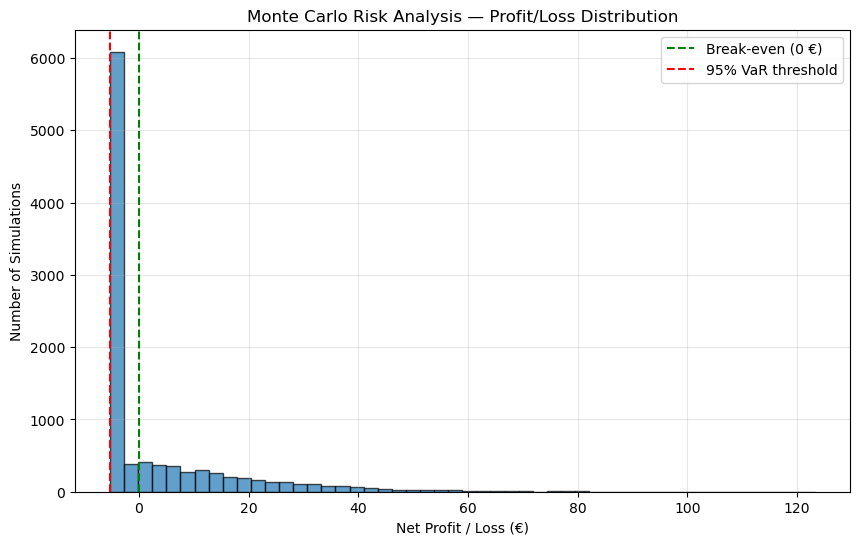

In [21]:
plt.figure(figsize=(10, 6))

plt.hist(
    risk_net_profits,
    bins=50,
    edgecolor="black",
    alpha=0.7
)

plt.axvline(
    0,
    color="green",
    linestyle="--",
    label="Break-even (0 €)"
)

plt.axvline(
    -risk_var_95,
    color="red",
    linestyle="--",
    label="95% VaR threshold"
)

plt.xlabel("Net Profit / Loss (€)")
plt.ylabel("Number of Simulations")
plt.title("Monte Carlo Risk Analysis — Profit/Loss Distribution")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## 9. Results and Conclusion

### Key Results

The Monte Carlo option pricing model was compared with the Black-Scholes analytical benchmark.

- Monte Carlo option price (50,000 simulations): approximately €5.33
- Black-Scholes option price: approximately €5.29
- Call option Delta: 0.4104
- Gamma: 0.0194
- Vega (1 percentage point): 0.3888
- Daily Theta: -0.0136
- Rho (1 percentage point): 0.3575
- 95% Value at Risk: €5.2934
- 95% Conditional Value at Risk: €5.2934

### Main Findings

1. Monte Carlo pricing produced an estimate close to the Black-Scholes analytical value.
2. Increasing the number of simulations generally improved the stability of the Monte Carlo estimate.
3. Call option values increased with higher volatility and higher underlying stock prices, while higher strike prices reduced their value.
4. The Option Greeks quantified the option's sensitivity to market parameters and time.
5. The long call position had a limited maximum loss equal to the premium paid, while its potential upside was theoretically unlimited.

### Conclusion

This project demonstrates how Monte Carlo simulation, analytical option pricing, sensitivity analysis, and risk measures can be combined to study a European call option.

The results illustrate both the usefulness of computational methods in quantitative finance and the importance of understanding model assumptions and limitations.
